***IMPORTING REQUIRED LIBRARIES***

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import statsmodels.api as sm

print("Libraries imported successfully.")

Libraries imported successfully.


***LOADING THE DATASET***

In [2]:
import pandas as pd

df = pd.read_csv("goodreads_best_books_2020_2025.csv")

df.head()

,isbn,asin,title,book_cover,author,avg_rating,num_ratings,num_reviews,year,genre,pages,publisher,language,description,url,scraped_at
0,NaN,B07QPHT8CB,The House in the Cerulean Sea,https://m.media-amazon.com/images/S/compressed...,T.J. Klune,4.36,1020173.0,152296.0,2020.0,Fantasy,393.0,Tor Books,English,A magical island. A dangerous task. A burning ...,https://www.goodreads.com/book/show/45047384-t...,2026-04-06T11:43:18Z
1,9.781636e+12,1635574048,House of Earth and Blood,https://m.media-amazon.com/images/S/compressed...,Sarah J. Maas,4.45,1183081.0,114958.0,2020.0,Fantasy,803.0,Bloomsbury Publishing,English,Bryce Quinlan had the perfect life-working har...,https://www.goodreads.com/book/show/44778083-h...,2026-04-06T11:43:25Z
2,9.780765e+12,0765387565,The Invisible Life of Addie LaRue,https://m.media-amazon.com/images/S/compressed...,V.E. Schwab,4.16,1551956.0,196463.0,2020.0,Fantasy,448.0,Tor Books,English,A Life No One Will Remember. A Story You Will ...,https://www.goodreads.com/book/show/50623864-t...,2026-04-06T11:43:30Z
3,9.780526e+12,0525559477,The Midnight Library,https://m.media-amazon.com/images/S/compressed...,Matt Haig,3.98,2528798.0,252564.0,2020.0,Fiction,288.0,Viking,English,Between life and death there is a library.When...,https://www.goodreads.com/book/show/52578297-t...,2026-04-06T11:43:36Z
4,NaN,NaN,American Dirt,https://m.media-amazon.com/images/S/compressed...,Jeanine Cummins,4.37,700358.0,53355.0,2020.0,Fiction,459.0,Flatiron Books,English,"Lydia lives in Acapulco. She has a son, Luca, ...",https://www.goodreads.com/book/show/45046527-a...,2026-04-06T11:43:44Z


***CHECKING THE SIZE OF THE DATASET***

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1799
Number of columns: 16


***Understanding the Dataset***

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
display(df.describe(include="all"))

Column names:
['isbn', 'asin', 'title', 'book_cover', 'author', 'avg_rating', 'num_ratings', 'num_reviews', 'year', 'genre', 'pages', 'publisher', 'language', 'description', 'url', 'scraped_at']

Data types:
isbn           float64
asin            object
title           object
book_cover      object
author          object
avg_rating     float64
num_ratings    float64
num_reviews    float64
year           float64
genre           object
pages          float64
publisher       object
language        object
description     object
url             object
scraped_at      object
dtype: object

Descriptive statistics:


,isbn,asin,title,book_cover,author,avg_rating,num_ratings,num_reviews,year,genre,pages,publisher,language,description,url,scraped_at
count,1.515000e+03,1724,1799,1796,1796,1796.000000,1.796000e+03,1796.000000,1796.000000,1795,1785.000000,1724,1799,1796,1799,1799
unique,NaN,1724,1789,1796,1182,NaN,NaN,NaN,NaN,51,NaN,408,2,1796,1799,1799
top,NaN,B07QPHT8CB,"Sorry, we couldn’t find the page you were look...",https://m.media-amazon.com/images/S/compressed...,Ali Hazelwood,NaN,NaN,NaN,NaN,Fantasy,NaN,Berkley,English,A magical island. A dangerous task. A burning ...,https://www.goodreads.com/book/show/45047384-t...,2026-04-06T11:43:18Z
freq,NaN,1,3,1,13,NaN,NaN,NaN,NaN,336,NaN,81,1798,1,1,1
mean,9.781316e+12,NaN,NaN,NaN,NaN,3.978474,1.349078e+05,15534.233296,2022.473831,NaN,367.431933,NaN,NaN,NaN,NaN,NaN
std,2.375751e+09,NaN,NaN,NaN,NaN,0.294029,2.840930e+05,29131.830080,1.885551,NaN,124.789392,NaN,NaN,NaN,NaN,NaN
min,9.780008e+12,NaN,NaN,NaN,NaN,2.920000,2.500000e+01,1.000000,1990.000000,NaN,12.000000,NaN,NaN,NaN,NaN,NaN
25%,9.780593e+12,NaN,NaN,NaN,NaN,3.780000,1.460825e+04,2041.250000,2021.000000,NaN,308.000000,NaN,NaN,NaN,NaN,NaN
50%,9.781250e+12,NaN,NaN,NaN,NaN,4.000000,4.492100e+04,6231.000000,2022.000000,NaN,359.000000,NaN,NaN,NaN,NaN,NaN
75%,9.781542e+12,NaN,NaN,NaN,NaN,4.180000,1.236918e+05,15965.250000,2024.000000,NaN,410.000000,NaN,NaN,NaN,NaN,NaN


***Inspecting the information***

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1799 entries, 0 to 1798
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   isbn         1515 non-null   float64
 1   asin         1724 non-null   object 
 2   title        1799 non-null   object 
 3   book_cover   1796 non-null   object 
 4   author       1796 non-null   object 
 5   avg_rating   1796 non-null   float64
 6   num_ratings  1796 non-null   float64
 7   num_reviews  1796 non-null   float64
 8   year         1796 non-null   float64
 9   genre        1795 non-null   object 
 10  pages        1785 non-null   float64
 11  publisher    1724 non-null   object 
 12  language     1799 non-null   object 
 13  description  1796 non-null   object 
 14  url          1799 non-null   object 
 15  scraped_at   1799 non-null   object 
dtypes: float64(6), object(10)
memory usage: 225.0+ KB


***Checking Missing Values***

In [6]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
isbn           284
asin            75
title            0
book_cover       3
author           3
avg_rating       3
num_ratings      3
num_reviews      3
year             3
genre            4
pages           14
publisher       75
language         0
description      3
url              0
scraped_at       0
dtype: int64


***Checking Duplicate Records***

In [7]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


***Identifying Invalid Scraper Records***

In [8]:
invalid_records = df[
    df["title"].astype(str).str.contains(
        "Sorry, we couldn’t find",
        case=False,
        na=False
    )
]

print("Invalid scraper records:", len(invalid_records))

display(invalid_records)

Invalid scraper records: 3


,isbn,asin,title,book_cover,author,avg_rating,num_ratings,num_reviews,year,genre,pages,publisher,language,description,url,scraped_at
1133,NaN,NaN,"Sorry, we couldn’t find the page you were look...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,English,NaN,https://www.goodreads.com/book/show/149131106-...,2026-04-06T13:44:30Z
1145,NaN,NaN,"Sorry, we couldn’t find the page you were look...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,English,NaN,https://www.goodreads.com/book/show/145937508-...,2026-04-06T13:45:34Z
1725,NaN,NaN,"Sorry, we couldn’t find the page you were look...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,English,NaN,https://www.goodreads.com/book/show/221979619-...,2026-04-06T15:17:45Z


***Removing invalid scraper records***

In [9]:
df = df[
    ~df["title"].astype(str).str.contains(
        "Sorry, we couldn’t find",
        case=False,
        na=False
    )
].copy()

print("Dataset size after removing invalid records:", df.shape)

Dataset size after removing invalid records: (1796, 16)


***Checking the Publication Years***

In [10]:
print("Minimum year:", df["year"].min())
print("Maximum year:", df["year"].max())

print("\nYear distribution:")
print(df["year"].value_counts().sort_index())

Minimum year: 1990.0
Maximum year: 2025.0

Year distribution:
year
1990.0      1
2014.0      1
2019.0      2
2020.0    299
2021.0    298
2022.0    299
2023.0    298
2024.0    299
2025.0    299
Name: count, dtype: int64


***Keeping books published between 2020 and 2025***

In [11]:
df = df[
    df["year"].between(2020, 2025)
].copy()

print("Dataset size after year filtering:", df.shape)

Dataset size after year filtering: (1792, 16)


***Handling the Missing Values***

In [13]:
df_clean = df.copy()

df_clean = df_clean.drop(
    columns=['isbn', 'asin', 'book_cover', 'url', 'scraped_at'],
    errors='ignore'
)

df_clean['author'] = df_clean['author'].fillna('Unknown')
df_clean['genre'] = df_clean['genre'].fillna('Unknown')
df_clean['publisher'] = df_clean['publisher'].fillna('Unknown')
df_clean['description'] = df_clean['description'].fillna('No description')

df_clean['avg_rating'] = df_clean['avg_rating'].fillna(
    df_clean['avg_rating'].median()
)

df_clean['num_ratings'] = df_clean['num_ratings'].fillna(
    df_clean['num_ratings'].median()
)

df_clean['num_reviews'] = df_clean['num_reviews'].fillna(
    df_clean['num_reviews'].median()
)

df_clean['year'] = df_clean['year'].fillna(
    df_clean['year'].median()
)

df_clean['pages'] = df_clean['pages'].fillna(
    df_clean['pages'].median()
)

print(df_clean.isnull().sum())

title          0
author         0
avg_rating     0
num_ratings    0
num_reviews    0
year           0
genre          0
pages          0
publisher      0
language       0
description    0
dtype: int64


***Creating the Target Variable***

In [14]:
best_seller_threshold = df["num_ratings"].quantile(0.75)

print(
    "Best-seller threshold:",
    best_seller_threshold
)

Best-seller threshold: 123691.75


***Creating the target***

In [15]:
df["best_seller"] = (
    df["num_ratings"] >= best_seller_threshold
).astype(int)

***Checking the distribution***

In [16]:
print(df["best_seller"].value_counts())

print("\nPercentage distribution:")
print(df["best_seller"].value_counts(normalize=True) * 100)

best_seller
0    1344
1     448
Name: count, dtype: int64

Percentage distribution:
best_seller
0    75.0
1    25.0
Name: proportion, dtype: float64


***VISUALISING TARGET CLASS DISTRIBUTION***

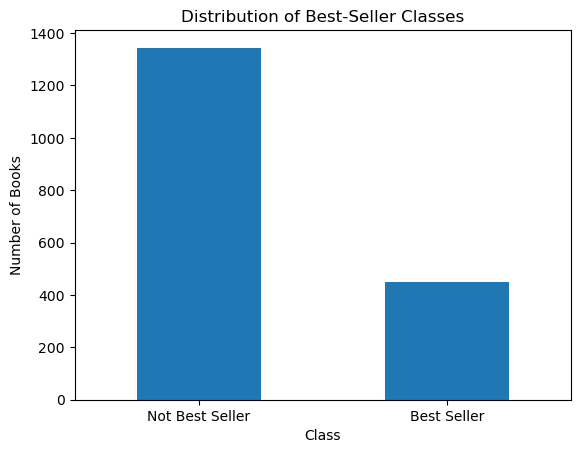

In [17]:
df["best_seller"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks(
    [0, 1],
    ["Not Best Seller", "Best Seller"],
    rotation=0
)

plt.ylabel("Number of Books")
plt.xlabel("Class")
plt.title("Distribution of Best-Seller Classes")

plt.show()

***DISTRIBUTION OF AVERAGE RATINGS***

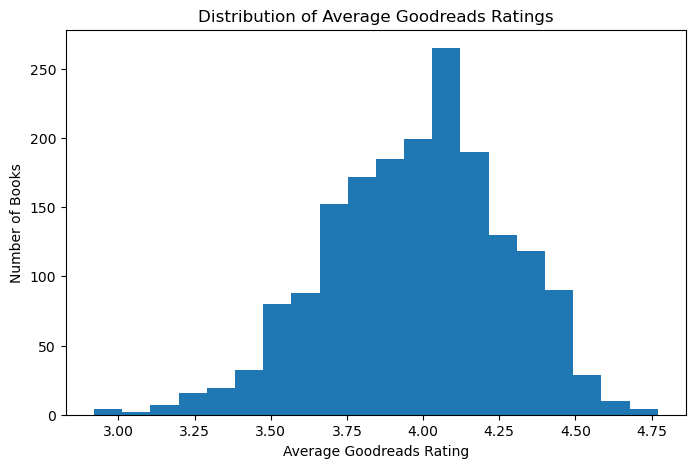

In [18]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["avg_rating"],
    bins=20
)

plt.xlabel("Average Goodreads Rating")
plt.ylabel("Number of Books")
plt.title("Distribution of Average Goodreads Ratings")

plt.show()

***VISUALISING Number of Ratings***

Text(0.5, 1.0, 'Distribution of Goodreads Rating Counts')

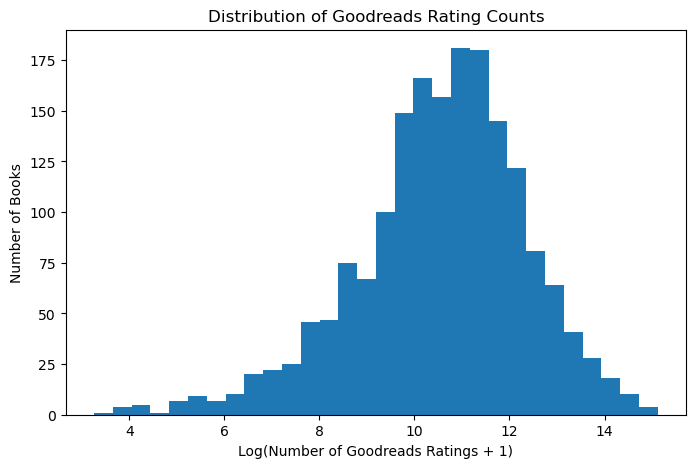

In [19]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(df["num_ratings"]),
    bins=30
)

plt.xlabel("Log(Number of Goodreads Ratings + 1)")
plt.ylabel("Number of Books")
plt.title("Distribution of Goodreads Rating Counts")

***DISTRIBUTION OF BOOK LENGTH***

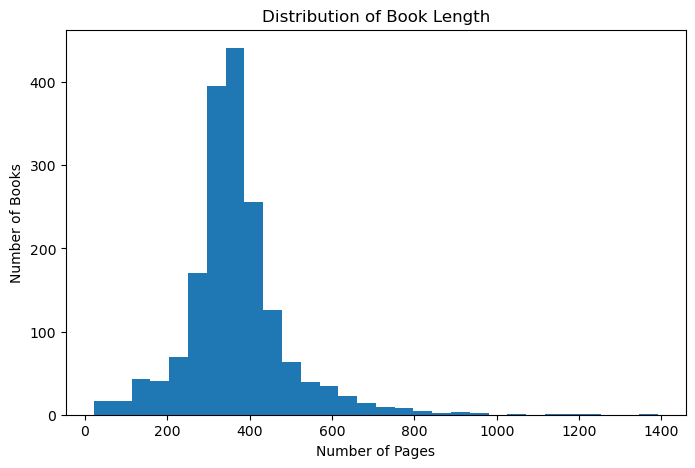

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["pages"],
    bins=30
)

plt.xlabel("Number of Pages")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Length")

plt.show()

***MOST COMMON GENRES***

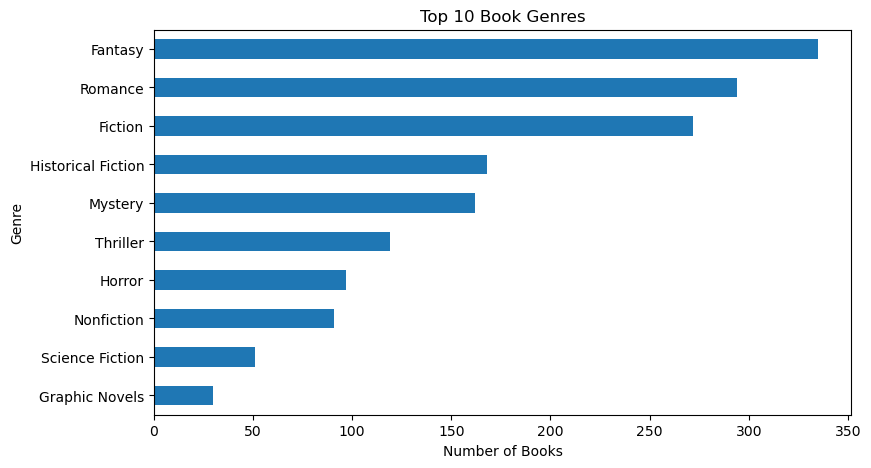

In [22]:
top_genres = df["genre"].value_counts().head(10)

plt.figure(figsize=(9, 5))

top_genres.sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of Books")
plt.ylabel("Genre")
plt.title("Top 10 Book Genres")

plt.show()

***COMPARE AVERAGE RATINGS BY TARGET***

In [23]:
print(
    df.groupby("best_seller")["avg_rating"].agg(
        ["mean", "median", "min", "max"]
    )
)

                 mean  median   min   max
best_seller                              
0            3.963914    3.98  2.92  4.77
1            4.022009    4.04  3.26  4.59


***Visualization COMPARE AVERAGE RATINGS BY TARGET***

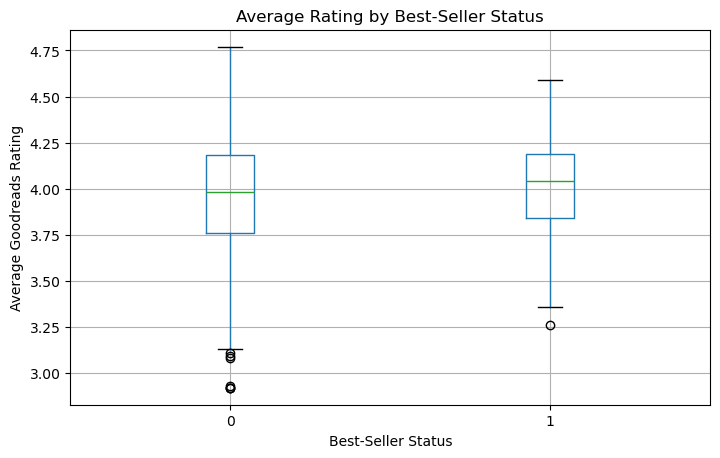

In [24]:
df.boxplot(
    column="avg_rating",
    by="best_seller",
    figsize=(8, 5)
)

plt.title("Average Rating by Best-Seller Status")
plt.suptitle("")
plt.xlabel("Best-Seller Status")
plt.ylabel("Average Goodreads Rating")

plt.show()

***Comparing Pages Between Classes***

In [25]:
print(
    df.groupby("best_seller")["pages"].agg(
        ["mean", "median", "min", "max"]
    )
)

                   mean  median   min     max
best_seller                                  
0            357.042761   352.0  22.0  1391.0
1            400.265625   379.0  61.0  1232.0


***CORRELATION ANALYSIS***

In [26]:
numeric_columns = [
    "avg_rating",
    "num_ratings",
    "num_reviews",
    "pages",
    "year",
    "best_seller"
]

correlation_matrix = df[numeric_columns].corr()

display(correlation_matrix)

,avg_rating,num_ratings,num_reviews,pages,year,best_seller
avg_rating,1.000000,0.124202,0.119787,0.267818,-0.044025,0.085557
num_ratings,0.124202,1.000000,0.968617,0.145342,-0.075232,0.597007
num_reviews,0.119787,0.968617,1.000000,0.144413,-0.046826,0.620944
pages,0.267818,0.145342,0.144413,1.000000,-0.033058,0.150884
year,-0.044025,-0.075232,-0.046826,-0.033058,1.000000,-0.059029
best_seller,0.085557,0.597007,0.620944,0.150884,-0.059029,1.000000


***Visualising CORRELATION ANALYSIS***

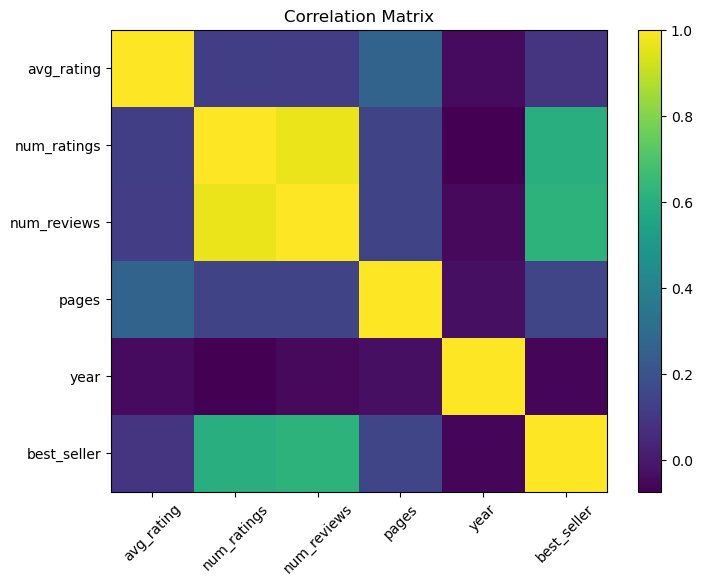

In [27]:
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Matrix")

plt.show()

***Feature Selection***

***Select Initial Features***

In [28]:
selected_features = [
    "avg_rating",
    "pages",
    "year",
    "genre",
    "publisher",
    "author"
]

X = df[selected_features].copy()

y = df["best_seller"].copy()

print("Selected features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Selected features:
['avg_rating', 'pages', 'year', 'genre', 'publisher', 'author']

Target:
best_seller


***GROUP RARE CATEGORIES***

In [30]:
def group_rare_categories(data, column, minimum_count):
    
    counts = data[column].value_counts()
    
    common_categories = counts[
        counts >= minimum_count
    ].index
    
    data[column] = data[column].where(
        data[column].isin(common_categories),
        "Other"
    )
    
    return data


X = group_rare_categories(
    X,
    "genre",
    10
)

X = group_rare_categories(
    X,
    "publisher",
    10
)

X = group_rare_categories(
    X,
    "author",
    5
)

print("Rare categories grouped successfully.")

Rare categories grouped successfully.


***Convert Categorical Variables***

In [31]:
X_encoded = pd.get_dummies(
    X,
    columns=[
        "genre",
        "publisher",
        "author"
    ],
    drop_first=True,
    dtype=float
)

print("Number of features after encoding:", X_encoded.shape[1])

display(X_encoded.head())

Number of features after encoding: 93


,avg_rating,pages,year,genre_Fantasy,genre_Fiction,genre_Graphic Novels,genre_Historical Fiction,genre_History,genre_Horror,genre_Memoir,...,author_Richard Osman,author_Riley Sager,author_Rina Kent,author_Ruth Ware,author_Seanan McGuire,author_Silvia Moreno-Garcia,author_Stephen King,author_T. Kingfisher,author_T.J. Klune,author_Tessa Bailey
0,4.36,393.0,2020.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,4.45,803.0,2020.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4.16,448.0,2020.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3.98,288.0,2020.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4.37,459.0,2020.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


***SPLIT DATA INTO TRAINING AND TESTING SETS***

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 1433
Testing observations: 359


***STANDARDISE FEATURES***

In [34]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature standardisation completed.")

Feature standardisation completed.


In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [37]:
df['description'] = df['description'].fillna('')

In [38]:
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df['description'])

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (1792, 5000)


In [40]:
X = tfidf.transform(df['description'].fillna(''))

print("Transformation completed successfully.")
print("Shape of transformed data:", X.shape)

Transformation completed successfully.
Shape of transformed data: (1792, 5000)


In [44]:
df['description'] = df['description'].fillna('')

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (1433, 17)
Testing dataset shape: (359, 17)


In [45]:
tfidf = TfidfVectorizer(max_features=5000)

X_train = tfidf.fit_transform(train_df['description'])
X_test = tfidf.transform(test_df['description'])

print("TF-IDF training shape:", X_train.shape)
print("TF-IDF testing shape:", X_test.shape)

TF-IDF training shape: (1433, 5000)
TF-IDF testing shape: (359, 5000)


In [46]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of TF-IDF features:", X_train.shape[1])

Training samples: 1433
Testing samples: 359
Number of TF-IDF features: 5000


***ADDING INTERCEPT TERM***

In [47]:
X_train_scaled = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

X_test_scaled = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

print("Intercept added.")
print("Training matrix shape:", X_train_scaled.shape)

Intercept added.
Training matrix shape: (1433, 94)


***Training Logistic Regression From Scratch***

In [49]:
from sklearn.linear_model import LogisticRegression

***SIGMOID FUNCTION***

In [50]:
def sigmoid(z):
    """
    Convert a linear prediction into a probability
    between 0 and 1.
    """
    
    # Prevent numerical overflow
    z = np.clip(z, -500, 500)
    
    return 1 / (1 + np.exp(-z))

In [51]:
print(sigmoid(0))
print(sigmoid(2))
print(sigmoid(-2))

0.5
0.8807970779778823
0.11920292202211755


***LOGISTIC REGRESSION FROM SCRATCH***

In [52]:
def train_logistic_regression(
    X,
    y,
    learning_rate=0.02,
    epochs=5000,
    l2=0.05,
    pos_weight=1.0
):
    
    
    weights = np.zeros(X.shape[1])
    
    
    
    sample_weights = np.where(
        y == 1,
        pos_weight,
        1.0
    )
    

    
    for epoch in range(epochs):
        
        z = X @ weights
        

        probabilities = sigmoid(z)
        
        
        gradient = (
            X.T @ (
                sample_weights *
                (probabilities - y)
            )
        ) / len(y)
        
        
        
        regularisation = l2 * np.r_[
            0,
            weights[1:]
        ]
        
        gradient += regularisation
        
        
        
        weights -= learning_rate * gradient
    
    
    return weights

***TRAINING BASELINE MODEL***

In [54]:
baseline_weights = train_logistic_regression(
    X_train_scaled,
    y_train.values,
    learning_rate=0.02,
    epochs=5000,
    l2=0.05,
    pos_weight=1.0
)

print("Baseline model trained successfully.")

Baseline model trained successfully.


***GENERATE BASELINE PREDICTIONS***

In [55]:
baseline_probabilities = sigmoid(
    X_test_scaled @ baseline_weights
)

# Probability >= 0.50 becomes class 1
baseline_predictions = (
    baseline_probabilities >= 0.50
).astype(int)

print("Predictions generated.")

Predictions generated.


***Evaluate the Model***

**CALCULATE ACCURACY**

In [59]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [60]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[0 0 0 0 0 0 0 0 0 0]


In [61]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 74.93 %


In [66]:
import pandas as pd

print("Actual test labels:")
print(pd.Series(y_test).value_counts())

print("\nPredicted labels:")
print(pd.Series(y_pred).value_counts())

Actual test labels:
best_seller
0    269
1     90
Name: count, dtype: int64

Predicted labels:
0    359
Name: count, dtype: int64


In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 74.93 %

Classification Report:
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       269
           1       0.00      0.00      0.00        90

    accuracy                           0.75       359
   macro avg       0.37      0.50      0.43       359
weighted avg       0.56      0.75      0.64       359



In [69]:
# Display the first five rows
display(df.head())

# Display the data types and missing values
print(df.info())

,isbn,asin,title,book_cover,author,avg_rating,num_ratings,num_reviews,year,genre,pages,publisher,language,description,url,scraped_at,best_seller
0,NaN,B07QPHT8CB,The House in the Cerulean Sea,https://m.media-amazon.com/images/S/compressed...,T.J. Klune,4.36,1020173.0,152296.0,2020.0,Fantasy,393.0,Tor Books,English,A magical island. A dangerous task. A burning ...,https://www.goodreads.com/book/show/45047384-t...,2026-04-06T11:43:18Z,1
1,9.781636e+12,1635574048,House of Earth and Blood,https://m.media-amazon.com/images/S/compressed...,Sarah J. Maas,4.45,1183081.0,114958.0,2020.0,Fantasy,803.0,Bloomsbury Publishing,English,Bryce Quinlan had the perfect life-working har...,https://www.goodreads.com/book/show/44778083-h...,2026-04-06T11:43:25Z,1
2,9.780765e+12,0765387565,The Invisible Life of Addie LaRue,https://m.media-amazon.com/images/S/compressed...,V.E. Schwab,4.16,1551956.0,196463.0,2020.0,Fantasy,448.0,Tor Books,English,A Life No One Will Remember. A Story You Will ...,https://www.goodreads.com/book/show/50623864-t...,2026-04-06T11:43:30Z,1
3,9.780526e+12,0525559477,The Midnight Library,https://m.media-amazon.com/images/S/compressed...,Matt Haig,3.98,2528798.0,252564.0,2020.0,Fiction,288.0,Viking,English,Between life and death there is a library.When...,https://www.goodreads.com/book/show/52578297-t...,2026-04-06T11:43:36Z,1
4,NaN,NaN,American Dirt,https://m.media-amazon.com/images/S/compressed...,Jeanine Cummins,4.37,700358.0,53355.0,2020.0,Fiction,459.0,Flatiron Books,English,"Lydia lives in Acapulco. She has a son, Luca, ...",https://www.goodreads.com/book/show/45046527-a...,2026-04-06T11:43:44Z,1


<class 'pandas.core.frame.DataFrame'>
Index: 1792 entries, 0 to 1798
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   isbn         1512 non-null   float64
 1   asin         1720 non-null   object 
 2   title        1792 non-null   object 
 3   book_cover   1792 non-null   object 
 4   author       1792 non-null   object 
 5   avg_rating   1792 non-null   float64
 6   num_ratings  1792 non-null   float64
 7   num_reviews  1792 non-null   float64
 8   year         1792 non-null   float64
 9   genre        1791 non-null   object 
 10  pages        1781 non-null   float64
 11  publisher    1720 non-null   object 
 12  language     1792 non-null   object 
 13  description  1792 non-null   object 
 14  url          1792 non-null   object 
 15  scraped_at   1792 non-null   object 
 16  best_seller  1792 non-null   int64  
dtypes: float64(6), int64(1), object(10)
memory usage: 252.0+ KB
None


In [70]:
print("Actual test labels:")
print(pd.Series(y_test).value_counts(dropna=False))

print("\nPredicted labels:")
print(pd.Series(y_pred).value_counts(dropna=False))

Actual test labels:
best_seller
0    269
1     90
Name: count, dtype: int64

Predicted labels:
0    359
Name: count, dtype: int64


***RETRAINING THE MODEL***

In [75]:
final_weights = train_logistic_regression(
    X_train_scaled,
    y_train.values,
    
    learning_rate=0.02,
    
    epochs=5000,
    
    l2=0.05,
    
    pos_weight=1.5
)

print("Retrained model completed.")

Retrained model completed.


***PREDICTING USING RETRAINED MODEL***

In [76]:
final_probabilities = sigmoid(
    X_test_scaled @ final_weights
)

final_predictions = (
    final_probabilities >= 0.40
).astype(int)

print("Final predictions generated.")

Final predictions generated.


***EVALUATING RETRAINED MODEL***

In [78]:
import numpy as np
import pandas as pd

print("NaN values in y_test:", pd.isna(y_test).sum())
print("NaN values in final_predictions:", pd.isna(final_predictions).sum())
print("NaN values in final_probabilities:", pd.isna(final_probabilities).sum())

print("Infinite values in probabilities:",
      np.isinf(np.asarray(final_probabilities)).sum())

NaN values in y_test: 0
NaN values in final_predictions: 0
NaN values in final_probabilities: 359
Infinite values in probabilities: 0


In [80]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Generate predictions
final_predictions = model.predict(X_test)

# Generate probabilities for the positive class
final_probabilities = model.predict_proba(X_test)[:, 1]

# Check for missing values
print("Missing probabilities:", np.isnan(final_probabilities).sum())

Missing probabilities: 0


In [82]:
final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_auc = roc_auc_score(
    y_test,
    final_probabilities
)

print("Final Model Results")
print("---------------------------")
print("Accuracy :", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall   :", round(final_recall, 4))
print("F1 Score :", round(final_f1, 4))
print("ROC-AUC  :", round(final_auc, 4))

Final Model Results
---------------------------
Accuracy : 0.7493
Precision: 0.0
Recall   : 0.0
F1 Score : 0.0
ROC-AUC  : 0.4943


***COMPARING BASELINE AND FINAL MODEL***

In [85]:
%whos

Variable                    Type                  Data/Info
-----------------------------------------------------------
LogisticRegression          type                  <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
StandardScaler              type                  <class 'sklearn.preproces<...>ng._data.StandardScaler'>
TfidfVectorizer             type                  <class 'sklearn.feature_e<...>on.text.TfidfVectorizer'>
X                           csr_matrix            <Compressed Sparse Row sp<...>4990)	0.08781536750736929
X_encoded                   DataFrame             Shape: (1792, 93)
X_test                      csr_matrix            <Compressed Sparse Row sp<...>4977)	0.05341181053522346
X_test_scaled               ndarray               359x94: 33746 elems, type `float64`, 269968 bytes (263.640625 kb)
X_train                     csr_matrix            <Compressed Sparse Row sp<...>1739)	0.13456030405117464
X_train_scaled              ndarray               1433x94: 1

In [86]:
print("Available variables:")

for name in [
    "model", "baseline_model", "logistic_model",
    "y_pred", "y_test", "X_test",
    "baseline_predictions", "final_predictions"
]:
    print(name, "exists" if name in globals() else "not defined")

Available variables:
model exists
baseline_model not defined
logistic_model not defined
y_pred exists
y_test exists
X_test exists
baseline_predictions exists
final_predictions exists


In [87]:
from sklearn.linear_model import LogisticRegression

# Train the baseline model
baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)

# Generate probabilities for ROC-AUC
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]

***FINAL CONFUSION MATRIX***

In [90]:
final_cm = confusion_matrix(
    y_test,
    final_predictions
)

print("Final Confusion Matrix:")
print(final_cm)

Final Confusion Matrix:
[[269   0]
 [ 90   0]]


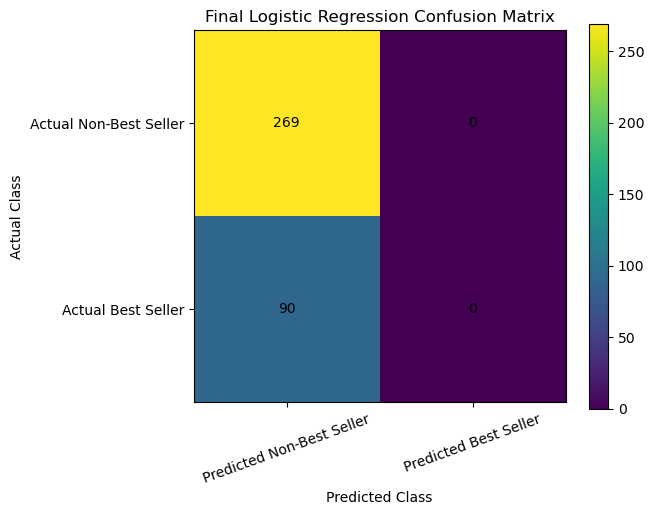

In [91]:
plt.figure(figsize=(6, 5))

plt.imshow(final_cm)

plt.colorbar()

plt.xticks(
    [0, 1],
    ["Predicted Non-Best Seller",
     "Predicted Best Seller"],
    rotation=20
)

plt.yticks(
    [0, 1],
    ["Actual Non-Best Seller",
     "Actual Best Seller"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Final Logistic Regression Confusion Matrix"
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            final_cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

*** ROC CURVE***

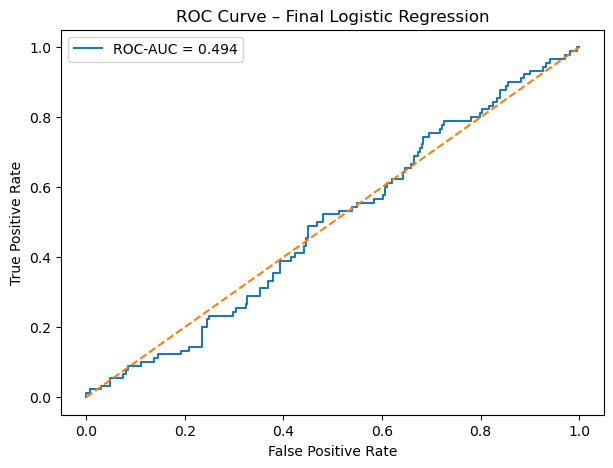

In [92]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    final_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {final_auc:.3f}"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve – Final Logistic Regression"
)

plt.legend()

plt.show()